# Visualizing Fire Scars Through False Color
## EDS 220 Homework Assignment #4


**Author:** [Priscilla Pierce](https://github.com/pr-scilla)

**Date:** November 21, 2026

**GitHub Repository Link:** https://github.com/pr-scilla/eds220-hwk4


## About

### Purpose

The January 2025 Eaton and Palisades fires consumed more than [38,000 acres](https://www.news.caloes.ca.gov/a-year-after-the-la-fires-pacific-palisades-and-altadena-communities-recover/) of Los Angeles County. Tens of thousands of residents were displaced, thousands of structures were destroyed, and large areas of the foothills and coast sustained severe damage.

This assignment explores the impacts of the Eaton and Palisades fires through data exploration and visualization of the burn scars in true color and false color (SWIR) imagery.

### Highlights

- Data exploration and data manipulation of Eaton and Palisades GeoDataFrame fire perimeter data using the GeoPandas library

- Exploring and wrangling Landsat Collection 2 Level-2 raster data using xarray and rioxarray libraries

- Merging fire perimeter vector data and Landsat Collection 2 Level-2 raster data

- Visualizing remote sensing data through map creation and false color imagery

### About the data

**Eaton and Palisades Fire Perimeter Data**

The perimeter shapefiles for the 2025 Eaton and Palisades fires were accessed through the [County of Los Angeles Open Data](https://data.lacounty.gov/) portal. The County of Los Angeles credits [CAL FIRE's Historical Fire Perimeter Dataset](https://www.arcgis.com/home/item.html?id=c3c10388e3b24cec8a954ba10458039d#overview) as the original source for the fire perimeter data. 


**Landsat Collection 2 Level-2 Data**

This assignment utilizes Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data collected by the Landsat 8 satellite, which has been simplified to include red, green, blue, near-infrared and shortwave infrared bands. The Landsat data were retrieved from the Microsoft Planetary Computer data catalog and clipped to an area surrounding the 2025 Eaton and Palisades fire perimeters by the EDS 220 instructing team. Data were accessed through the course shared [Google Drive](https://drive.google.com/drive/folders/1USqhiMLyN8GE05B8WJmHabviJGnmAsLP).


### References and Data Sources

[EDS 220: Working with Environmental Datasets](https://meds-eds-220.github.io/MEDS-eds-220-course/) Instructor: Carmen Galaz García

County of Los Angeles. (2026). Eaton_Perimeter_20250121 [Dataset]. County of Los Angeles Open Data. Retrieved November 2026 from (https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about)

County of Los Angeles. (2026). Palisades_Perimieter_20250121 [Dataset]. County of Los Angeles Open Data. Retrieved November 2026 from https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about

[Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2). (2025). Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data [Dataset]. Landsat Collection 2 Level-2. Retrieved November 2026 from course shared Google Drive (https://drive.google.com/drive/folders/1USqhiMLyN8GE05B8WJmHabviJGnmAsLP)

In [23]:
# Import libraries

import numpy as np
import geopandas as gpd

import xarray as xr
import rioxarray as rioxr

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## Eaton and Palisades Fire Perimeter Exploration

In [ ]:
# Load Eaton and Palisades perimeters
eaton = gpd.read_file('data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp')

palisades = gpd.read_file('data/Palisades_Perimeter_20250121/Palisades_Perimieter_20250121.shp')

# Verify that CRSs match
assert eaton.crs == palisades.crs

df = [eaton, palisades]
fire = ["Eaton", "Palisades"]

for data, name in zip(df, fire):
    if data.crs.is_geographic == True:
        print(f"The {name} perimeter data utilizes a geographic CRS")
        print(f"The CRS of the {name} perimeter is: {data.crs}")
    elif data.crs.is_projected == True:
        print(f"The {name} perimeter data utilizes a projected CRS")
        print(f"The CRS of the fire perimeter is: {data.crs}")
    else:
        print(f"No CRS associated with {name} data")

    print(f"The type of geometry in the {name} perimeter data is: {data.geom_type}")
    print(f"There are {data.shape[0]} rows and {data.shape[1]} columns in the {name} GeoDataFrame.")
    print("\n")


The Eaton perimeter data utilizes a geographic CRS
The CRS of the Eaton perimeter is: EPSG:4269
The type of geometry in the Eaton perimeter data is: 0    MultiPolygon
dtype: object
There are 1 rows and 24 columns in the Eaton GeoDataFrame


The Palisades perimeter data utilizes a geographic CRS
The CRS of the Palisades perimeter is: EPSG:4269
The type of geometry in the Palisades perimeter data is: 0    MultiPolygon
dtype: object
There are 1 rows and 24 columns in the Palisades GeoDataFrame




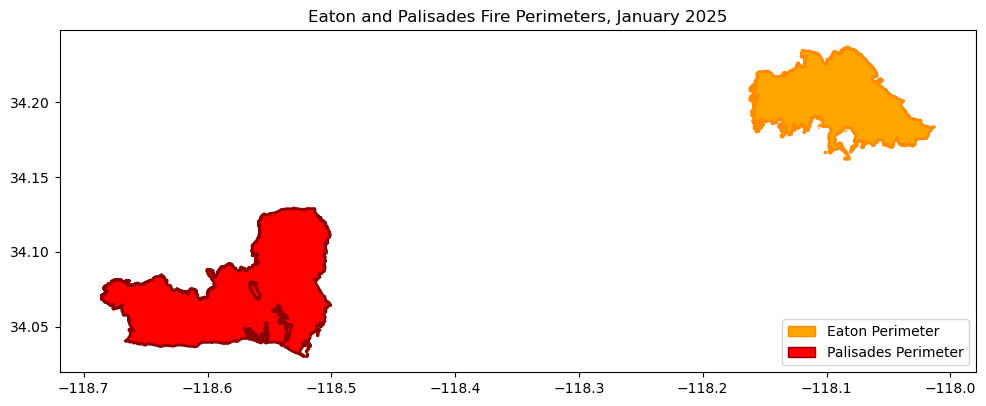

In [ ]:
# Visualize the Eaton and Palisades fire polygons

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

eaton.plot(ax=ax, color='orange', edgecolor='darkorange',
                     linewidth=2, label='Eaton perimeter')
palisades.plot(ax=ax, color='red', edgecolor='darkred',
               linewidth=2, label='Palisades perimeter')

# Create patches corresponding to Eaton and Palisades polygons to appear in legend
plot_scale = [Patch(facecolor='orange', edgecolor='darkorange', 
                         label='Eaton Perimeter'),
               Patch(facecolor='red', edgecolor= 'darkred',
                         label='Palisades Perimeter')]


ax.set_title('Eaton and Palisades Fire Perimeters, January 2025')
ax.legend(handles = plot_scale, loc = 'lower right')
plt.tight_layout()

plt.show()

The Eaton and Palisades fire perimeter data use the EPSG:4269 coordinate reference system, which is geographic (uses latitude and longitude coordinates in degrees). The fire perimeter geometries are multipolygons.

## Landsat Data Exploration

In [20]:
# Open landsat dataset
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

**Variables:**

The variables of the landsat xarray are the light bands red, green, blue, nir80 (near infrared) and swir22 (shortwave infrared), stored as floats. The variable `spatial_ref` is referenced in the grid mapping of the light band variables and includes spatial reference information. 

**Dimensions:**

There are two dimensions: (y: 1418, x: 2742)

**Coordinates:**

There are three coordinates listed in the xarray: y, x, and time (datetime). The y and x coordinates utilize the EPSG:32611 CRS, which is a projected coordinate system with meters as units. The landsat data has a 30 meter resolution.


## Restore Landsat Data Geospatial Information

In [ ]:
# Print CRS of landsat data
print("The CRS of the landsat data is: ", landsat.rio.crs)

The CRS of the landsat data is:  None


The landsat xarray currently does not have recognizable geospatial information.

In [ ]:
# Print CRS stored in spatial_ref variable
print(f"The spatial_ref variable in the landsat dataset stores the CRS as: \n"
      f"{landsat['spatial_ref'].crs_wkt}")


The spatial_ref variable in the landsat dataset stores the CRS as: 
PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [36]:
# Recover geospatial information

landsat_geo = landsat.rio.write_crs(landsat['spatial_ref'].crs_wkt)

print(f"The recovered CRS of the landsat data is: {landsat_geo.rio.crs}")

The recovered CRS of the landsat data is: EPSG:32611


The landsat data originally did not have recognizable associated geospatial information. The CRS was recovered by assigning the CRS from the `spatial_ref` variable in the landsat xarray back to the landsat xarray using `rio.write_crs`.

## Create a True Color Image